# Notebook 12: Series temporales — forecasting de un paso por ventana de lags (Caso 9)

Todo sale de `qml_v2.timeseries`; los resultados se guardan en `data/output/metrics/fair_timeseries_*.csv`.

## Pregunta
¿Un kernel cuántico ZZ sobre la **ventana de lags** predice el siguiente valor mejor que regresores clásicos que ven **los mismos lags**?

No es un *bake-off* contra ARIMA ni Prophet: es la misma pregunta que en clasificación y regresión (¿el mapa ZZ está alineado con el generador del objetivo?) trasladada al dominio secuencial.

## Protocolo
- **Tabla A (lags emparejados):** $n_{\rm lags}=n_{\rm qubits}=2$ para QK-SVR (ZZ, `reps=2`) frente a Ridge, SVR-RBF y Gradient Boosting.
- **Tabla B (mismo $n$, clásicos con más información):** los clásicos reciben además 4 lags extra, media y desviación de la ventana y, en SKG, la hora (con su codificación cíclica).
- **Partición temporal:** entrenamiento = pasado (70 %), prueba = futuro (30 %). Sin mezcla aleatoria.
- **Repeticiones:** `zz_lag` y `sine` usan ventanas contiguas distintas; `skg_speed` usa **un corredor distinto por repetición** (cada corredor es una única serie de 144 lecturas de 5 minutos).

## Datasets
| Dataset | Naturaleza | Hipótesis |
|---|---|---|
| `zz_lag` | ventanas de ángulos; objetivo $=\langle ZZ\rangle$ de la ventana | favorece al kernel ZZ **por construcción** |
| `sine` | serie periódica clásica + ruido | favorece a lo clásico |
| `skg_speed` | velocidades reales de corredores de SKG | clásico; sirve de caso práctico |

## §1 — Imports y configuración

In [1]:
import contextlib
import io
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

POCS = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "qml_v2").exists())
sys.path.insert(0, str(POCS))

from qml_v2 import timeseries as ts
from qml_v2.regression import make_quantum_native_regression

FIGURES = POCS / "data" / "output" / "figures"
METRICS = POCS / "data" / "output" / "metrics"
DATASETS = ("zz_lag", "sine", "skg_speed")
AZUL, NAVY, GRIS, CARBON, CLARO = "#219BC3", "#0E4A75", "#858591", "#4A4A57", "#C0C0C8"

cfg = ts.TSConfig()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Protocolo:", cfg)

Protocolo: TSConfig(n_qubits=2, n_lags=2, n_extra_lags=4, zz_reps=2, entanglement='full', svr_C=10.0, svr_epsilon=0.1, n_total=160, test_size=0.3, n_repeats=5, random_state=42, n_estimators=100)


## §2 — Las tres series
`zz_lag` no tiene dinámica temporal: las ventanas son ángulos independientes y el objetivo es una función exacta de ellas. Se dibuja en el plano de los dos lags. En `sine` y `skg_speed` se sombrea el tramo de prueba (el futuro).

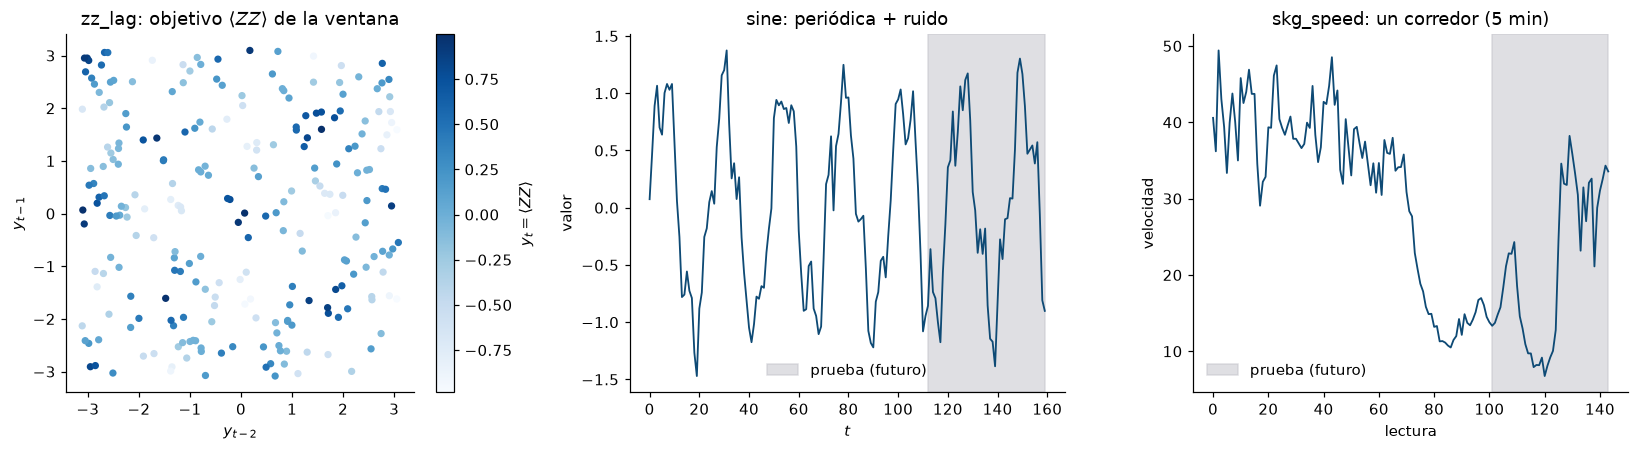

Corredor SKG: 144 lecturas -> 138 muestras con lags (< n_total=160: se usa entera)


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

X, y = make_quantum_native_regression(
    n_samples=240, n_qubits=cfg.n_qubits, reps=cfg.zz_reps, random_state=cfg.random_state
)
sc = axes[0].scatter(X[:, 0], X[:, 1], c=y, cmap="Blues", s=14)
axes[0].set(title=r"zz_lag: objetivo $\langle ZZ\rangle$ de la ventana", xlabel="$y_{t-2}$", ylabel="$y_{t-1}$")
fig.colorbar(sc, ax=axes[0], label=r"$y_t=\langle ZZ\rangle$")

sine = ts.make_sine_series(n_samples=cfg.n_total, random_state=cfg.random_state)
speed, hour = ts.load_skg_corridors(1)[0]
series = {"sine: periódica + ruido": (sine, "$t$"), "skg_speed: un corredor (5 min)": (speed, "lectura")}
for ax, (title, (values, xlabel)) in zip(axes[1:], series.items()):
    cut = len(values) - ts.time_split_indices(len(values), cfg.test_size)[1].size
    ax.plot(values, color=NAVY, lw=1.2)
    ax.axvspan(cut, len(values) - 1, color=CLARO, alpha=0.5, label="prueba (futuro)")
    ax.set(title=title, xlabel=xlabel, ylabel="valor" if "sine" in title else "velocidad")
    ax.legend(frameon=False)

plt.tight_layout()
plt.savefig(FIGURES / "12_series_datasets.png", dpi=150, bbox_inches="tight", metadata={"paleta": "unir"})
plt.show()
print(
    f"Corredor SKG: {len(speed)} lecturas -> {len(speed) - cfg.n_lags - cfg.n_extra_lags} muestras con lags (< n_total={cfg.n_total}: se usa entera)"
)

## §3 — Ejecución del protocolo
`run_all` guarda un CSV de resumen y otro por repetición para cada dataset, y el informe `BUSINESS/timeseries_v2_results.md`.

In [3]:
with contextlib.redirect_stdout(io.StringIO()):
    ts.run_all(cfg, datasets=DATASETS)

summary = pd.concat([pd.read_csv(METRICS / f"fair_timeseries_{d}.csv") for d in DATASETS], ignore_index=True)
references = pd.read_csv(METRICS / "fair_timeseries_references.csv").set_index(["dataset", "reference"])["mae_mean"]
summary["MAE"] = summary["mae_mean"].round(3).astype(str) + " ± " + summary["mae_std"].round(3).astype(str)
summary["R2"] = summary["r2_mean"].round(3)
for table in ("A_matched_lags", "B_matched_n_rich_features"):
    print(f"\n=== {table} ===")
    display(
        summary[summary["table"] == table][["dataset", "model", "MAE", "R2", "n_features", "n_repeats"]].reset_index(
            drop=True
        )
    )
print("\n=== Referencias ingenuas (MAE, mismas ventanas de prueba) ===")
display(references.unstack().round(3))


=== A_matched_lags ===


,dataset,model,MAE,R2,n_features,n_repeats
0,zz_lag,QK-SVR-ZZ,0.056 ± 0.007,0.981,2,5
1,zz_lag,Ridge,0.414 ± 0.037,-0.118,2,5
2,zz_lag,SVR-RBF,0.435 ± 0.038,-0.239,2,5
3,zz_lag,GradientBoosting,0.465 ± 0.031,-0.620,2,5
4,sine,SVR-RBF,0.26 ± 0.031,0.826,2,5
5,sine,Ridge,0.266 ± 0.032,0.815,2,5
6,sine,GradientBoosting,0.294 ± 0.042,0.768,2,5
7,sine,QK-SVR-ZZ,0.662 ± 0.057,-0.175,2,5
8,skg_speed,Ridge,2.799 ± 0.632,0.047,2,5
9,skg_speed,GradientBoosting,3.187 ± 0.766,-0.054,2,5



=== B_matched_n_rich_features ===


,dataset,model,MAE,R2,n_features,n_repeats
0,sine,SVR-RBF [full features],0.244 ± 0.02,0.830,8,5
1,sine,Ridge [full features],0.245 ± 0.025,0.834,8,5
2,sine,GradientBoosting [full features],0.253 ± 0.027,0.822,8,5
3,skg_speed,GradientBoosting [full features],3.242 ± 1.181,-0.013,11,5
4,skg_speed,Ridge [full features],4.899 ± 1.383,-1.479,11,5
5,skg_speed,SVR-RBF [full features],5.876 ± 2.656,-2.786,11,5



=== Referencias ingenuas (MAE, mismas ventanas de prueba) ===


reference,persistence,train_mean
dataset,,
sine,0.287,0.658
skg_speed,2.749,13.614
zz_lag,1.754,0.404


## §4 — MAE por dataset (menor es mejor)

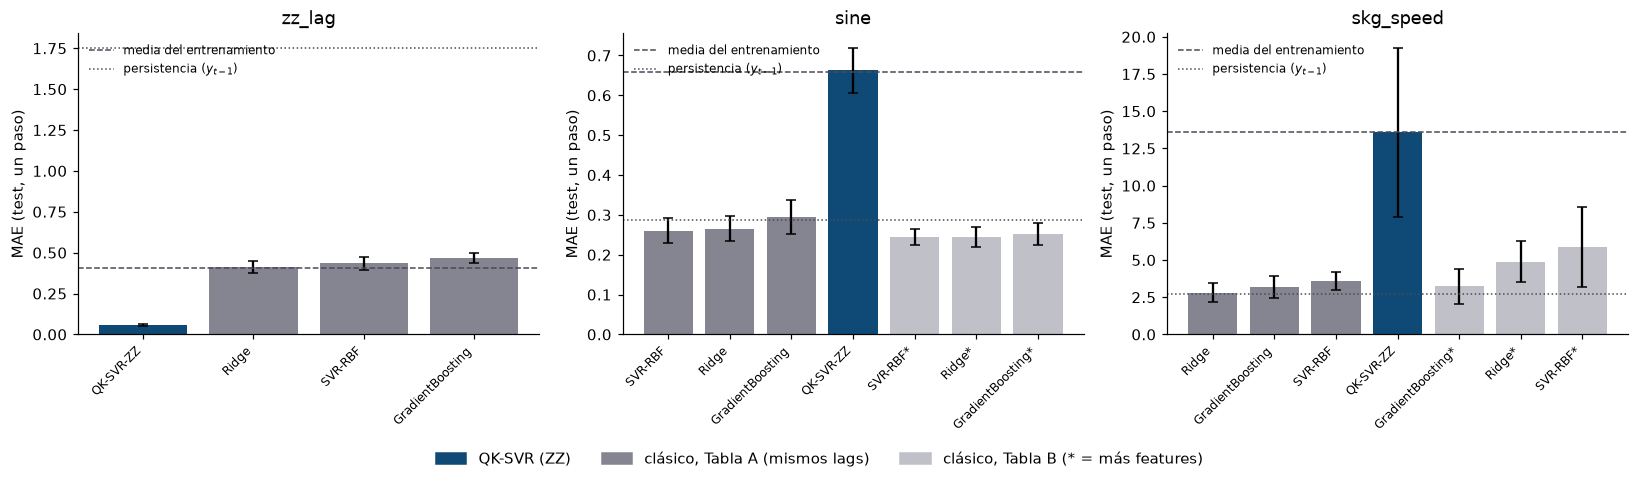

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, dataset in zip(axes, DATASETS):
    block = summary[summary["dataset"] == dataset].copy()
    block["order"] = block["table"].map({"A_matched_lags": 0, "B_matched_n_rich_features": 1})
    block = block.sort_values(["order", "mae_mean"]).reset_index(drop=True)
    colors = [NAVY if "ZZ" in m else (CLARO if "full" in m else GRIS) for m in block["model"]]
    ax.bar(range(len(block)), block["mae_mean"], yerr=block["mae_std"], color=colors, capsize=3)
    ax.set_xticks(range(len(block)))
    ax.set_xticklabels(
        block["model"].str.replace(" [full features]", "*", regex=False), rotation=45, ha="right", fontsize=8
    )
    ax.axhline(references[dataset, "train_mean"], color=CARBON, ls="--", lw=1, label="media del entrenamiento")
    ax.axhline(references[dataset, "persistence"], color=CARBON, ls=":", lw=1, label=r"persistencia ($y_{t-1}$)")
    ax.set(title=dataset, ylabel="MAE (test, un paso)")
    ax.legend(frameon=False, fontsize=8, loc="upper left")

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (NAVY, GRIS, CLARO)]
fig.legend(
    handles,
    ["QK-SVR (ZZ)", "clásico, Tabla A (mismos lags)", "clásico, Tabla B (* = más features)"],
    loc="lower center",
    ncol=3,
    frameon=False,
)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.savefig(FIGURES / "12_series_mae.png", dpi=150, bbox_inches="tight", metadata={"paleta": "unir"})
plt.show()

## §5 — Lectura (generada desde los CSV)

In [5]:
for dataset in DATASETS:
    block = summary[(summary["dataset"] == dataset) & (summary["table"] == "A_matched_lags")]
    qk = block[block["model"].str.contains("ZZ")].iloc[0]
    best = block[~block["model"].str.contains("ZZ")].sort_values("mae_mean").iloc[0]
    gain = 100 * (best["mae_mean"] - qk["mae_mean"]) / best["mae_mean"]
    print(
        f"{dataset:10s} QK-SVR {qk['mae_mean']:.3f} vs {best['model']} {best['mae_mean']:.3f}  ->  mejora relativa del MAE: {gain:+.1f} %"
    )
    print(
        f"{'':10s} media del entrenamiento {references[dataset, 'train_mean']:.3f}; persistencia {references[dataset, 'persistence']:.3f}"
    )

zz_lag     QK-SVR 0.056 vs Ridge 0.414  ->  mejora relativa del MAE: +86.6 %
           media del entrenamiento 0.404; persistencia 1.754
sine       QK-SVR 0.662 vs SVR-RBF 0.260  ->  mejora relativa del MAE: -154.9 %
           media del entrenamiento 0.658; persistencia 0.287
skg_speed  QK-SVR 13.592 vs Ridge 2.799  ->  mejora relativa del MAE: -385.6 %
           media del entrenamiento 13.614; persistencia 2.749


### Cómo leerlo
- **`zz_lag`** es el único caso donde gana el kernel cuántico y gana *por construcción*: el objetivo es $\langle ZZ\rangle$ de la propia ventana, igual que en el régimen nativo de clasificación y regresión.
- **`sine`** y **`skg_speed`** los gana un modelo clásico con los mismos lags. Fuera del régimen nativo el QK-SVR se queda en el MAE de predecir la media del entrenamiento (línea discontinua): con 2 qubits y ventanas de ángulos, el kernel no extrapola al futuro.
- **Tabla B en SKG:** más features (hora incluida) no mejoran al mejor clásico de la Tabla A; con 97 muestras de entrenamiento 11 variables sobreajustan.
- **Límites:** 2 qubits (dos lags) frente a ventanas clásicas más largas; simulación exacta (sin ruido); `skg_speed` son 5 series de 138 muestras. No se compara con ARIMA/Prophet.